Heurystyka 'ostatnia próbka' MSE: 0.00631
Heurystyka 'średnia z treningu' MSE: 0.51725

--- EKSPERYMENT A: Liczba jednostek ukrytych (GRU, OKNO=30) ---
Zrobiono: GRU_h8 | Parametry: 273 | MSE: 0.00380 ± 0.00004 | Czas: 7.95s
Zrobiono: GRU_h16 | Parametry: 929 | MSE: 0.00374 ± 0.00002 | Czas: 6.08s
Zrobiono: GRU_h32 | Parametry: 3393 | MSE: 0.00376 ± 0.00001 | Czas: 7.08s
Zrobiono: GRU_h64 | Parametry: 12929 | MSE: 0.00375 ± 0.00008 | Czas: 10.93s

--- EKSPERYMENT B: Długość okna (GRU, hidden=32) ---
Zrobiono: GRU_w10 | Parametry: 3393 | MSE: 0.00414 ± 0.00019 | Czas: 2.75s
Zrobiono: GRU_w30 | Parametry: 3393 | MSE: 0.00376 ± 0.00001 | Czas: 7.23s
Zrobiono: GRU_w60 | Parametry: 3393 | MSE: 0.00343 ± 0.00021 | Czas: 14.77s
Zrobiono: GRU_w120 | Parametry: 3393 | MSE: 0.00344 ± 0.00019 | Czas: 25.61s

--- EKSPERYMENT C: Typ komórki dla okna 10 i 120 (hidden=32) ---
Zrobiono: RNN_w10 | Parametry: 1153 | MSE: 0.00417 ± 0.00025 | Czas: 1.39s
Zrobiono: LSTM_w10 | Parametry: 4513 | MSE: 0.00415

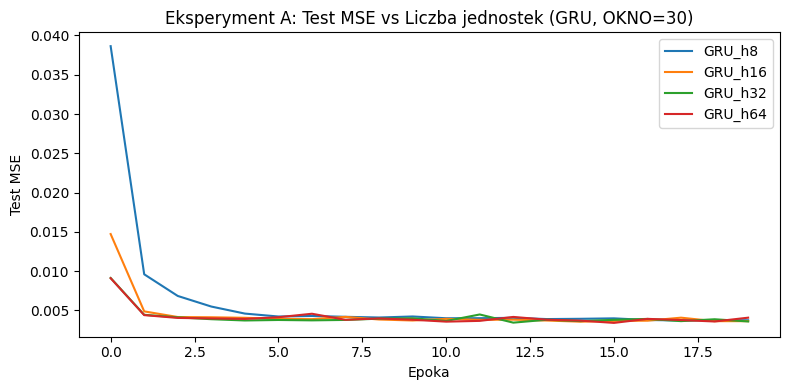

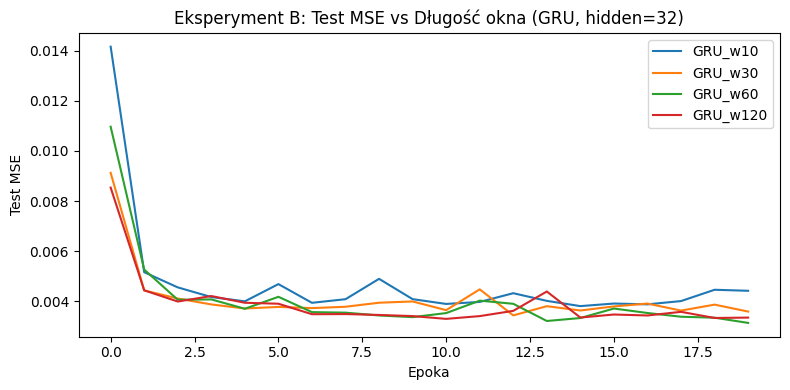

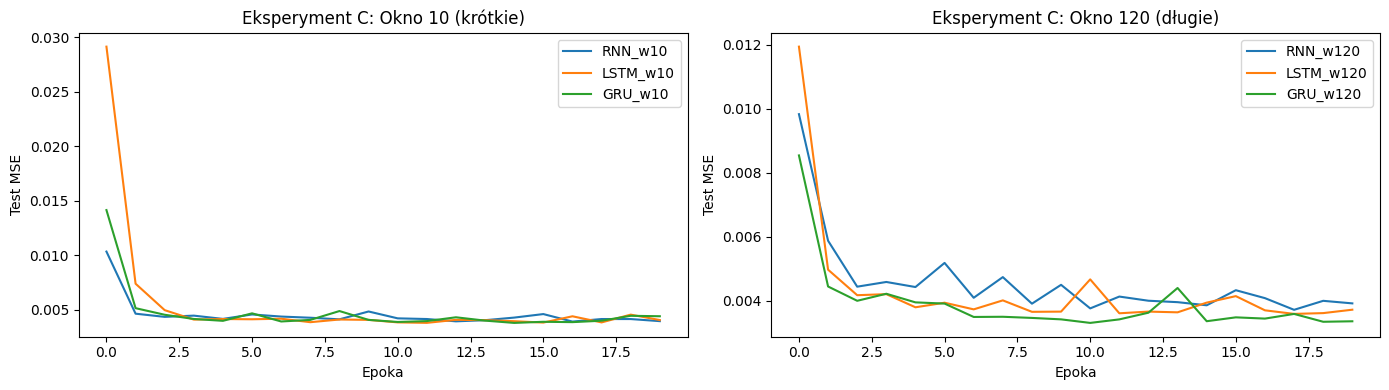

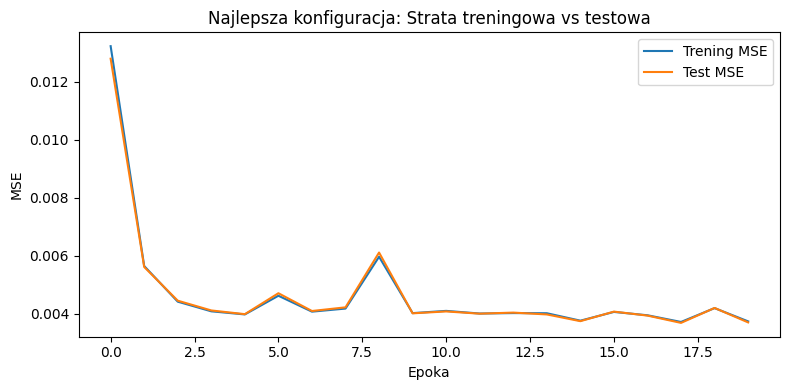

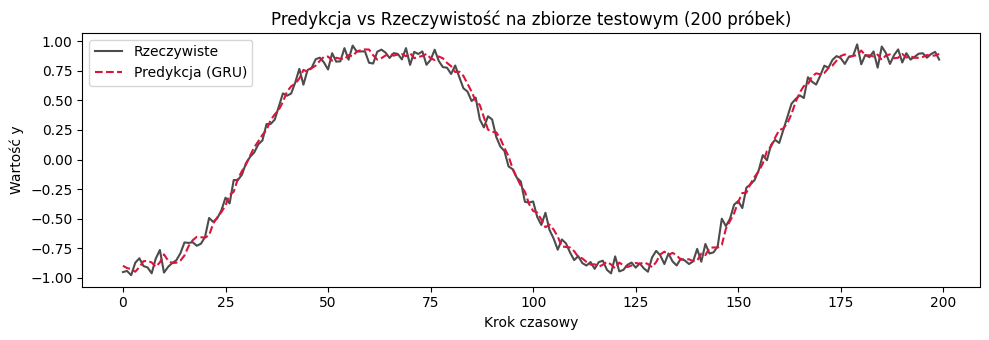

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1 * np.sin(3 * t) + 0.05 * np.random.randn(n)
    return y.astype(np.float32)

def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i + okno])
        Y.append(seria[i + okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y

class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn_cls = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn_cls(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_test = []
    hist_train = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            hist_train.append(strata(model(Xtr), Ytr).item())
            hist_test.append(strata(model(Xte), Yte).item())
    return hist_test, hist_train

def przygotuj_dane(seria, okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8 * len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte

np.random.seed(0)
seria_danych = generuj_szereg(2000)

Xtr30, Ytr30, Xte30, Yte30 = przygotuj_dane(seria_danych, okno=30)
baseline_last = ((Yte30 - Xte30[:, -1])**2).mean().item()
baseline_mean = ((Yte30 - Ytr30.mean())**2).mean().item()
print(f"Heurystyka 'ostatnia próbka' MSE: {baseline_last:.5f}")
print(f"Heurystyka 'średnia z treningu' MSE: {baseline_mean:.5f}")

seeds = [0, 1, 2]

def uruchom_serie(konfiguracje, zmienna_okno=False):
    tabela = []
    krzywe_test = {}
    modele_zapisane = {}

    for cfg in konfiguracje:
        typ = cfg.get('typ', 'GRU')
        hidden = cfg.get('hidden', 32)
        okno = cfg.get('okno', 30)
        etykieta = cfg['etykieta']

        if zmienna_okno:
            Xtr, Ytr, Xte, Yte = przygotuj_dane(seria_danych, okno)
        else:
            Xtr, Ytr, Xte, Yte = Xtr30, Ytr30, Xte30, Yte30

        mse_list = []
        czas_list = []
        krzywe_seed = []
        ostatni_model = None
        ostatnia_para_krzywych = None

        for s in seeds:
            torch.manual_seed(s)
            np.random.seed(s)
            model = ModelRNN(hidden=hidden, typ=typ)
            t0 = time.perf_counter()
            h_te, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
            dt = time.perf_counter() - t0

            czas_list.append(dt)
            mse_list.append(np.mean(h_te[-5:]))
            krzywe_seed.append(h_te)
            ostatni_model = model
            ostatnia_para_krzywych = (h_te, h_tr)

        param_count = sum(p.numel() for p in model.parameters())
        srednia_krzywa = np.mean(krzywe_seed, axis=0)
        krzywe_test[etykieta] = srednia_krzywa
        modele_zapisane[etykieta] = (ostatni_model, ostatnia_para_krzywych, Xte, Yte)

        tabela.append({
            'etykieta': etykieta,
            'parametry': param_count,
            'mse_srednia': np.mean(mse_list),
            'mse_std': np.std(mse_list),
            'czas': np.mean(czas_list)
        })
        print(f"Zrobiono: {etykieta} | Parametry: {param_count} | MSE: {np.mean(mse_list):.5f} ± {np.std(mse_list):.5f} | Czas: {np.mean(czas_list):.2f}s")
    return tabela, krzywe_test, modele_zapisane

print("\n--- EKSPERYMENT A: Liczba jednostek ukrytych (GRU, OKNO=30) ---")
cfgs_A = [{'hidden': h, 'typ': 'GRU', 'okno': 30, 'etykieta': f'GRU_h{h}'} for h in [8, 16, 32, 64]]
tab_A, krzywe_A, _ = uruchom_serie(cfgs_A, zmienna_okno=False)

print("\n--- EKSPERYMENT B: Długość okna (GRU, hidden=32) ---")
cfgs_B = [{'hidden': 32, 'typ': 'GRU', 'okno': w, 'etykieta': f'GRU_w{w}'} for w in [10, 30, 60, 120]]
tab_B, krzywe_B, _ = uruchom_serie(cfgs_B, zmienna_okno=True)

print("\n--- EKSPERYMENT C: Typ komórki dla okna 10 i 120 (hidden=32) ---")
cfgs_C = [
    {'hidden': 32, 'typ': t, 'okno': w, 'etykieta': f'{t}_w{w}'}
    for w in [10, 120] for t in ['RNN', 'LSTM', 'GRU']
]
tab_C, krzywe_C, modele_C = uruchom_serie(cfgs_C, zmienna_okno=True)

plt.figure(figsize=(8, 4))
for k, v in krzywe_A.items():
    plt.plot(v, label=k)
plt.title('Eksperyment A: Test MSE vs Liczba jednostek (GRU, OKNO=30)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.tight_layout()
plt.savefig('eksperyment_A.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 4))
for k, v in krzywe_B.items():
    plt.plot(v, label=k)
plt.title('Eksperyment B: Test MSE vs Długość okna (GRU, hidden=32)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.tight_layout()
plt.savefig('eksperyment_B.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for k in ['RNN_w10', 'LSTM_w10', 'GRU_w10']:
    axes[0].plot(krzywe_C[k], label=k)
axes[0].set_title('Eksperyment C: Okno 10 (krótkie)')
axes[0].set_xlabel('Epoka')
axes[0].set_ylabel('Test MSE')
axes[0].legend()

for k in ['RNN_w120', 'LSTM_w120', 'GRU_w120']:
    axes[1].plot(krzywe_C[k], label=k)
axes[1].set_title('Eksperyment C: Okno 120 (długie)')
axes[1].set_xlabel('Epoka')
axes[1].set_ylabel('Test MSE')
axes[1].legend()
plt.tight_layout()
plt.savefig('eksperyment_C.png', dpi=150)
plt.show()

najlepszy_model, (te_loss, tr_loss), Xte_best, Yte_best = modele_C['GRU_w10']

plt.figure(figsize=(8, 4))
plt.plot(tr_loss, label='Trening MSE')
plt.plot(te_loss, label='Test MSE')
plt.title('Najlepsza konfiguracja: Strata treningowa vs testowa')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.savefig('najlepszy_model_strata.png', dpi=150)
plt.show()

najlepszy_model.eval()
with torch.no_grad():
    pred = najlepszy_model(Xte_best).cpu().numpy().ravel()
rzeczywiste = Yte_best.cpu().numpy().ravel()

plt.figure(figsize=(10, 3.5))
plt.plot(rzeczywiste[:200], label='Rzeczywiste', color='black', alpha=0.7)
plt.plot(pred[:200], label='Predykcja (GRU)', color='crimson', linestyle='--')
plt.title('Predykcja vs Rzeczywistość na zbiorze testowym (200 próbek)')
plt.xlabel('Krok czasowy')
plt.ylabel('Wartość y')
plt.legend()
plt.tight_layout()
plt.savefig('predykcja_vs_rzeczywiste.png', dpi=150)
plt.show()